# P3 · Frozen CLAP audio–text scoring
**Team G16 · Thi Ngo**

DEAM audio → 10 s windows → frozen CLAP → prompt cosine → `clap_<Mood>` for P4.

## 0 · Setup

In [1]:
import os, sys, glob, json, time, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import librosa
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from IPython.display import display

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

PROJECT_DIR  = os.environ.get('P3_PROJECT_DIR', '/content/drive/MyDrive/ECE539-mood-music')
DATA_ZIP_DIR = os.path.join(PROJECT_DIR, 'data')
LOCAL_DATA   = os.environ.get('P3_LOCAL_DATA', '/content/deam')
OUT_DIR      = os.path.join(PROJECT_DIR, 'outputs', 'p3')
P2_OUT_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'p2')
P1_DIRS      = [os.environ.get('P3_P1_DIR', '/content/drive/MyDrive/ECE539_P1'),
                '/content/drive/MyDrive/Colab Notebooks/ECE539_P1']
REPO_RAW     = 'https://raw.githubusercontent.com/hsniko0522/ECE539-mood-music-recommender/main'

CLAP_ID         = 'laion/larger_clap_music_and_speech'
CACHE_DIR       = os.path.join(PROJECT_DIR, 'cache', CLAP_ID.split('/')[-1])
WINDOW_S       = 10.0
MIN_TAIL_S      = 3.0
BATCH_WINDOWS   = 32
EMBED_ALL_AUDIO = os.environ.get('P3_EMBED_ALL', '1') == '1'
TOP_K           = 10
MIDPOINT        = 5.0
for d in (CACHE_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)
print('device:', DEVICE, '| torch', torch.__version__)

device: cpu | torch 2.15.0+cpu


## 1 · Data

In [2]:
def unzip_all(src_dir, dst_dir, skip=('feature',)):
    os.makedirs(dst_dir, exist_ok=True)
    todo = sorted(glob.glob(os.path.join(src_dir, '*.zip')))
    if not todo:
        raise FileNotFoundError(f'No .zip files in {src_dir}. Put DEAM_audio.zip there first (see P2 cell 1a).')
    done = set()
    while todo:
        z = todo.pop(0)
        if z in done or any(s in os.path.basename(z).lower() for s in skip):
            done.add(z)
            continue
        marker = os.path.join(dst_dir, '.unzipped_' + os.path.basename(z))
        if not os.path.exists(marker):
            print('unzipping', os.path.basename(z), '...')
            with zipfile.ZipFile(z) as zf:
                zf.extractall(dst_dir)
            open(marker, 'w').close()
        done.add(z)
        todo += [p for p in glob.glob(os.path.join(dst_dir, '**', '*.zip'), recursive=True) if p not in done]

def read_repo_csv(rel_path):
    for p in (Path.cwd().parent / rel_path, Path.cwd() / rel_path):
        if p.exists():
            return pd.read_csv(p), str(p)
    url = f'{REPO_RAW}/{rel_path}'
    with urllib.request.urlopen(url, timeout=30) as r:
        return pd.read_csv(r), url

def load_split_and_labels():
    split_files = [f for d in P1_DIRS for f in sorted(glob.glob(os.path.join(d, 'splits', 'song_split_ids*.csv')))]
    label_files = sorted({f for root in [LOCAL_DATA] + [os.path.join(d, 'data') for d in P1_DIRS] if os.path.isdir(root)
                          for f in glob.glob(os.path.join(root, '**', '*static_annotations_averaged_songs*.csv'),
                                             recursive=True)})
    if split_files and label_files:
        split = pd.read_csv(split_files[0])
        split.columns = [c.strip().lower() for c in split.columns]
        labels = []
        for f in label_files:
            df = pd.read_csv(f, skipinitialspace=True)
            df.columns = [c.strip().lower() for c in df.columns]
            labels.append(df[['song_id', 'valence_mean', 'arousal_mean']])
        labels = pd.concat(labels).dropna().drop_duplicates('song_id')
        labels = labels.rename(columns={'valence_mean': 'valence_true', 'arousal_mean': 'arousal_true'})
        out = split[['song_id', 'split']].merge(labels, on='song_id', how='inner', validate='one_to_one')
        source = f'P1 split ({split_files[0]}) + DEAM annotations'
    else:
        va, source = read_repo_csv('p2/va_predictions.csv')
        out = va[['song_id', 'split', 'valence_true', 'arousal_true']].copy()
        source = f'P1 split and labels via P2 file {source}'
    out['song_id'] = out['song_id'].astype(int)
    out['split'] = out['split'].astype(str).str.strip().str.lower().replace({'val': 'dev', 'validation': 'dev'})
    assert out['song_id'].is_unique and out['split'].isin(['train', 'dev', 'test']).all()
    return out.sort_values('song_id').reset_index(drop=True), source

unzip_all(DATA_ZIP_DIR, LOCAL_DATA)
audio_paths = {int(Path(p).stem): p
               for ext in ('mp3', 'wav')
               for p in glob.glob(os.path.join(LOCAL_DATA, '**', f'*.{ext}'), recursive=True)
               if Path(p).stem.isdigit()}
songs, SPLIT_SOURCE = load_split_and_labels()
songs['path'] = songs['song_id'].map(audio_paths)
missing = songs[songs['path'].isna()]
print(f'audio files: {len(audio_paths)} | split source: {SPLIT_SOURCE}')
print(f'P1 songs: {len(songs)} | with audio: {songs.path.notna().sum()} | missing audio: {len(missing)}')
if len(missing):
    print('WARNING: songs without audio will have no CLAP score, e.g.', missing.song_id.head(10).tolist())
songs = songs[songs['path'].notna()].reset_index(drop=True)
print(songs.groupby('split')[['valence_true', 'arousal_true']].agg(['count', 'mean', 'std']).round(2).to_string())

audio files: 1802 | split source: P1 split and labels via P2 file p2/va_predictions.csv
P1 songs: 500 | with audio: 500 | missing audio: 0
      valence_true             arousal_true            
             count  mean   std        count  mean   std
split                                                  
dev             75  4.75  1.09           75  4.92  1.24
test            75  4.90  1.24           75  4.88  1.33
train          350  4.95  1.15          350  4.87  1.27


## 2 · Frozen CLAP
`larger_clap_music` is broken on Hugging Face, so we use `larger_clap_music_and_speech` (see README).

In [3]:
from transformers import ClapModel, ClapProcessor

clap = ClapModel.from_pretrained(CLAP_ID).to(DEVICE).eval()
processor = ClapProcessor.from_pretrained(CLAP_ID)
for p in clap.parameters():
    p.requires_grad_(False)
SR = processor.feature_extractor.sampling_rate
WIN = int(WINDOW_S * SR)
assert abs(processor.feature_extractor.max_length_s - WINDOW_S) < 1e-6, 'window length must match CLAP input length'

def _pooled(out):
    return out if isinstance(out, torch.Tensor) else out.pooler_output

@torch.no_grad()
def embed_text(prompts):
    tok = processor.tokenizer(list(prompts), padding=True, return_tensors='pt').to(DEVICE)
    return F.normalize(_pooled(clap.get_text_features(**tok)).float(), dim=-1).cpu().numpy()

@torch.no_grad()
def embed_windows(windows):
    feats = processor.feature_extractor(windows, sampling_rate=SR, return_tensors='pt')
    inputs = {k: v.to(DEVICE) for k, v in feats.items() if k in ('input_features', 'is_longer')}
    return F.normalize(_pooled(clap.get_audio_features(**inputs)).float(), dim=-1).cpu().numpy()

def song_windows(path):
    wav, _ = librosa.load(path, sr=SR, mono=True)
    wins = [wav[i:i + WIN] for i in range(0, len(wav), WIN)]
    return [w for w in wins if len(w) >= MIN_TAIL_S * SR] or [wav]

def embed_song(path):
    wins = song_windows(path)
    emb = np.concatenate([embed_windows(wins[i:i + BATCH_WINDOWS]) for i in range(0, len(wins), BATCH_WINDOWS)])
    if not np.isfinite(emb).all():
        raise ValueError('non-finite CLAP embedding')
    return emb.astype(np.float16)

t = np.arange(WIN) / SR
calm = 0.1 * np.sin(2 * np.pi * 220 * t) * (0.6 + 0.4 * np.sin(2 * np.pi * 0.2 * t))
rng = np.random.default_rng(0)
loud = 0.8 * rng.standard_normal(WIN) * ((t * 4) % 1 < 0.25)
a = embed_windows([calm.astype(np.float32), loud.astype(np.float32)])
tx = embed_text(['soft, calm, quiet music', 'loud, fast, aggressive noise'])
assert a.shape == (2, 512) and np.allclose(np.linalg.norm(a, axis=1), 1, atol=1e-3)
chk = embed_text(['sad piano ballad', 'loud heavy metal', 'a dog barking', 'calm, relaxing music'])
text_cos = (chk @ chk.T)[~np.eye(4, dtype=bool)].mean()
print(f'mean cosine between 4 unrelated prompts: {text_cos:.3f}')
assert text_cos < 0.9, f'{CLAP_ID} text embeddings have collapsed (mean cosine {text_cos:.3f}); use another checkpoint'
print(f'CLAP ok: {sum(p.numel() for p in clap.parameters()) / 1e6:.0f}M frozen parameters, {a.shape[1]}-d embeddings, '
      f'{SR} Hz, {WINDOW_S:.0f} s windows')
print('cosine, rows = [calm tone, noise bursts], cols = ["soft calm", "loud fast"]:')
print(np.round(a @ tx.T, 3))

mean cosine between 4 unrelated prompts: 0.128
CLAP ok: 194M frozen parameters, 512-d embeddings, 48000 Hz, 10 s windows
cosine, rows = [calm tone, noise bursts], cols = ["soft calm", "loud fast"]:
[[ 0.238  0.062]
 [-0.113  0.332]]


In [4]:
cache_path = lambda sid: os.path.join(CACHE_DIR, f'{sid}.npy')
embed_ids = sorted(audio_paths) if EMBED_ALL_AUDIO else songs['song_id'].tolist()
todo = [s for s in embed_ids if not os.path.exists(cache_path(s))]
print(f'{len(embed_ids) - len(todo)} songs already cached, {len(todo)} to embed')
failed, t0 = [], time.time()
for i, sid in enumerate(todo, 1):
    try:
        np.save(cache_path(sid), embed_song(audio_paths[sid]))
    except Exception as e:
        failed.append((sid, repr(e)))
    if i % 50 == 0 or i == len(todo):
        rate = i / (time.time() - t0)
        print(f'{i}/{len(todo)}  {rate:.2f} songs/s  ETA {(len(todo) - i) / rate / 60:.1f} min')
if failed:
    print(f'{len(failed)} songs failed, e.g.', failed[:3])
    pd.DataFrame(failed, columns=['song_id', 'error']).to_csv(os.path.join(OUT_DIR, 'clap_failed.csv'), index=False)

emb_ids = [s for s in embed_ids if os.path.exists(cache_path(s))]
win_embs = {s: np.load(cache_path(s)).astype(np.float32) for s in emb_ids}
EMB = np.stack([win_embs[s].mean(axis=0) for s in emb_ids])
N_WIN = np.array([len(win_embs[s]) for s in emb_ids])
os.makedirs(OUT_DIR, exist_ok=True)
np.savez_compressed(os.path.join(OUT_DIR, 'clap_audio_embeddings.npz'),
                    song_id=np.array(emb_ids), emb=EMB.astype(np.float16), n_windows=N_WIN)
row_of = {s: i for i, s in enumerate(emb_ids)}
songs = songs[songs.song_id.isin(row_of)].reset_index(drop=True)
print(f'embeddings {EMB.shape} | windows per song: median {np.median(N_WIN):.0f}, max {N_WIN.max()} '
      f'| P1 songs with embeddings: {len(songs)}')

500 songs already cached, 0 to embed


embeddings (500, 512) | windows per song: median 5, max 54 | P1 songs with embeddings: 500


## 3 · Prompts

In [5]:
MOODS = {
    'Relax':   {'valence': 6.5, 'arousal': 2.5},
    'Study':   {'valence': 5.5, 'arousal': 3.0},
    'Workout': {'valence': 7.0, 'arousal': 8.0},
    'Happy':   {'valence': 8.0, 'arousal': 6.5},
    'Sad':     {'valence': 2.5, 'arousal': 3.0},
}
PROMPT_BANK = {
    'Relax': {
        'p4_original': 'calm, relaxing music',
        'activity':    'relaxing music for unwinding after a long day',
        'acoustic':    'slow, soft and peaceful music',
        'genre':       'ambient music with gentle piano and soft synth pads',
        'scene':       'soothing music for a quiet evening at home',
        'one_word':    'relaxing',
    },
    'Study': {
        'p4_original': 'gentle, unobtrusive music for studying',
        'activity':    'background music for studying and concentrating',
        'acoustic':    'instrumental music without vocals, steady and calm',
        'genre':       'lo-fi hip hop beats',
        'scene':       'soft piano music for reading in a library',
        'one_word':    'studying',
    },
    'Workout': {
        'p4_original': 'energetic music for exercising',
        'activity':    'high-energy music for a workout at the gym',
        'acoustic':    'fast, loud music with a driving beat',
        'genre':       'intense electronic dance music with heavy bass',
        'scene':       'pumping rock music for running',
        'one_word':    'energetic',
    },
    'Happy': {
        'p4_original': 'happy, upbeat music',
        'activity':    'cheerful music for a party with friends',
        'acoustic':    'bright, major-key music with a bouncy rhythm',
        'genre':       'joyful pop song',
        'scene':       'feel-good music for a sunny road trip',
        'one_word':    'happy',
    },
    'Sad': {
        'p4_original': 'sad, reflective music',
        'activity':    'melancholic music for being alone on a rainy day',
        'acoustic':    'slow, minor-key music with mournful strings',
        'genre':       'sad piano ballad',
        'scene':       'heartbreaking music for after a breakup',
        'one_word':    'sad',
    },
}
assert set(PROMPT_BANK) == set(MOODS)
prompts = pd.DataFrame([dict(mood=m, style=s, prompt=p, prompt_id=f'{m}__{s}')
                        for m, bank in PROMPT_BANK.items() for s, p in bank.items()])
TXT = embed_text(prompts['prompt'])

cand_rows, cand_vecs = [], []
for m in MOODS:
    idx = np.flatnonzero(prompts['mood'].to_numpy() == m)
    cand_rows += prompts.iloc[idx].to_dict('records')
    cand_vecs += list(TXT[idx])
    v = TXT[idx].mean(axis=0)
    cand_vecs.append(v / np.linalg.norm(v))
    cand_rows.append(dict(mood=m, style='ensemble', prompt=' | '.join(PROMPT_BANK[m].values()), prompt_id=f'{m}__ensemble'))
candidates = pd.DataFrame(cand_rows)
CAND_TXT = np.stack(cand_vecs)
PER_MOOD = len(candidates) // len(MOODS)

SCORES = pd.DataFrame(EMB @ CAND_TXT.T, columns=candidates['prompt_id'])
SCORES.insert(0, 'song_id', emb_ids)
print(f'{len(prompts)} prompts + {len(MOODS)} ensembles scored on {len(SCORES)} songs')

sim = TXT @ TXT.T
same = prompts['mood'].to_numpy()[:, None] == prompts['mood'].to_numpy()[None, :]
off = ~np.eye(len(TXT), dtype=bool)
print(f'text-text cosine: same mood {sim[same & off].mean():.3f} | different moods {sim[~same].mean():.3f}')

30 prompts + 5 ensembles scored on 500 songs
text-text cosine: same mood 0.570 | different moods 0.396


## 4 · Prompt comparison (train + dev)

In [6]:
def emotion_similarity(v, a, mood):
    t = MOODS[mood]
    return 1 - np.sqrt(((v - t['valence']) / 8) ** 2 + ((a - t['arousal']) / 8) ** 2) / np.sqrt(2)

def in_quadrant(v, a, mood):
    t = MOODS[mood]
    return ((v - MIDPOINT) * np.sign(t['valence'] - MIDPOINT) > 0) & ((a - MIDPOINT) * np.sign(t['arousal'] - MIDPOINT) > 0)

def hit_at_k(scores, hits, k=TOP_K):
    order = np.argsort(-np.asarray(scores), kind='stable')[:k]
    return float(np.asarray(hits)[order].mean())

lab = songs[['song_id', 'split', 'valence_true', 'arousal_true']].merge(SCORES, on='song_id', validate='one_to_one')
lab = lab.sort_values('song_id').reset_index(drop=True)
pool = lab[lab.split.isin(['train', 'dev'])].reset_index(drop=True)
dev = lab[lab.split == 'dev'].reset_index(drop=True)
print(f'tuning pool: {len(pool)} songs (train {int((pool.split == "train").sum())}, dev {len(dev)}) | test held out: '
      f'{int((lab.split == "test").sum())}')

def prompt_metrics(df_pool, df_dev, col, mood):
    v, a, s = df_pool.valence_true.to_numpy(), df_pool.arousal_true.to_numpy(), df_pool[col].to_numpy()
    q = in_quadrant(v, a, mood)
    qd = in_quadrant(df_dev.valence_true.to_numpy(), df_dev.arousal_true.to_numpy(), mood)
    return dict(
        rho_target=spearmanr(s, emotion_similarity(v, a, mood))[0],
        rho_valence=spearmanr(s, v)[0],
        rho_arousal=spearmanr(s, a)[0],
        auc_quadrant=roc_auc_score(q, s) if 0 < q.sum() < len(q) else np.nan,
        hit10_pool=hit_at_k(s, q), chance_pool=q.mean(),
        hit10_dev=hit_at_k(df_dev[col].to_numpy(), qd), chance_dev=qd.mean(),
    )

comparison = pd.DataFrame([dict(mood=r.mood, style=r.style, prompt_id=r.prompt_id, prompt=r.prompt,
                                **prompt_metrics(pool, dev, r.prompt_id, r.mood))
                           for r in candidates.itertuples()])
best_idx = comparison.groupby('mood', sort=False)['rho_target'].idxmax()
comparison['selected'] = comparison.index.isin(best_idx)
SELECTED = {m: comparison.loc[i, 'prompt_id'] for m, i in best_idx.items()}

show = ['mood', 'style', 'prompt', 'rho_target', 'rho_valence', 'rho_arousal', 'auc_quadrant',
        'hit10_pool', 'chance_pool', 'hit10_dev', 'chance_dev', 'selected']
display(comparison[show].round(3))
print('selected per mood (max rho_target on train+dev):')
for m, pid in SELECTED.items():
    r = comparison.set_index('prompt_id').loc[pid]
    print(f'  {m:8s} {r["style"]:12s} rho={r["rho_target"]:.3f}  AUC={r["auc_quadrant"]:.3f}  "{r["prompt"][:70]}"')

tuning pool: 425 songs (train 350, dev 75) | test held out: 75


,mood,style,prompt,rho_target,rho_valence,rho_arousal,auc_quadrant,hit10_pool,chance_pool,hit10_dev,chance_dev,selected
0,Relax,p4_original,"calm, relaxing music",0.185,-0.301,-0.348,0.571,0.1,0.106,0.0,0.093,False
1,Relax,activity,relaxing music for unwinding after a long day,0.142,-0.286,-0.321,0.554,0.1,0.106,0.0,0.093,False
2,Relax,acoustic,"slow, soft and peaceful music",0.247,-0.412,-0.472,0.582,0.1,0.106,0.1,0.093,False
3,Relax,genre,ambient music with gentle piano and soft synth...,0.181,-0.380,-0.401,0.515,0.0,0.106,0.0,0.093,False
4,Relax,scene,soothing music for a quiet evening at home,0.184,-0.368,-0.412,0.566,0.1,0.106,0.0,0.093,False
5,Relax,one_word,relaxing,0.255,-0.304,-0.412,0.594,0.0,0.106,0.1,0.093,True
6,Relax,ensemble,"calm, relaxing music | relaxing music for unwi...",0.209,-0.362,-0.416,0.565,0.0,0.106,0.1,0.093,False
7,Study,p4_original,"gentle, unobtrusive music for studying",0.059,-0.209,-0.176,0.442,0.1,0.106,0.0,0.093,False
8,Study,activity,background music for studying and concentrating,0.050,-0.150,-0.153,0.453,0.0,0.106,0.0,0.093,False
9,Study,acoustic,"instrumental music without vocals, steady and ...",0.198,-0.237,-0.248,0.540,0.2,0.106,0.0,0.093,True


selected per mood (max rho_target on train+dev):
  Relax    one_word     rho=0.255  AUC=0.594  "relaxing"
  Study    acoustic     rho=0.198  AUC=0.540  "instrumental music without vocals, steady and calm"
  Workout  scene        rho=0.483  AUC=0.720  "pumping rock music for running"
  Happy    activity     rho=0.487  AUC=0.742  "cheerful music for a party with friends"
  Sad      acoustic     rho=0.545  AUC=0.756  "slow, minor-key music with mournful strings"


In [7]:
style_summary = (comparison.groupby('style')[['rho_target', 'auc_quadrant', 'hit10_pool', 'hit10_dev']]
                 .mean().sort_values('rho_target', ascending=False))
style_summary['n_times_selected'] = comparison.loc[comparison.selected, 'style'].value_counts().reindex(style_summary.index).fillna(0).astype(int)
display(style_summary.round(3))

p4 = comparison[comparison['style'] == 'p4_original'].set_index('mood')
sel = comparison[comparison.selected].set_index('mood')
display(pd.DataFrame({'P4 prompt rho': p4.rho_target, 'selected rho': sel.rho_target,
                      'P4 prompt AUC': p4.auc_quadrant, 'selected AUC': sel.auc_quadrant,
                      'selected style': sel['style']}).round(3))

,rho_target,auc_quadrant,hit10_pool,hit10_dev,n_times_selected
style,,,,,
acoustic,0.328,0.643,0.54,0.36,2
ensemble,0.282,0.615,0.50,0.36,0
activity,0.254,0.607,0.46,0.28,1
genre,0.241,0.604,0.48,0.28,0
scene,0.233,0.578,0.40,0.20,1
one_word,0.188,0.589,0.42,0.36,1
p4_original,0.167,0.560,0.40,0.30,0


,P4 prompt rho,selected rho,P4 prompt AUC,selected AUC,selected style
mood,,,,,
Relax,0.185,0.255,0.571,0.594,one_word
Study,0.059,0.198,0.442,0.540,acoustic
Workout,0.115,0.483,0.582,0.720,scene
Happy,0.088,0.487,0.544,0.742,activity
Sad,0.389,0.545,0.662,0.756,acoustic


### 4a · Raw vs. centred

In [8]:
MOOD_LIST = list(MOODS)
def final_scores(df, mode):
    raw = df[[SELECTED[m] for m in MOOD_LIST]].to_numpy()
    out = raw - raw.mean(axis=1, keepdims=True) if mode == 'centred' else raw
    return pd.DataFrame(out, columns=[f'clap_{m}' for m in MOOD_LIST], index=df.index)

mode_rows = []
for mode in ('raw', 'centred'):
    fp, fd = final_scores(pool, mode), final_scores(dev, mode)
    tmp_p, tmp_d = pd.concat([pool, fp], axis=1), pd.concat([dev, fd], axis=1)
    for m in MOOD_LIST:
        mode_rows.append(dict(mode=mode, mood=m, **prompt_metrics(tmp_p, tmp_d, f'clap_{m}', m)))
    corr = np.corrcoef(fp.to_numpy().T)
    mode_rows.append(dict(mode=mode, mood='(mean inter-mood corr)', rho_target=corr[~np.eye(5, dtype=bool)].mean()))
mode_cmp = pd.DataFrame(mode_rows)
mode_summary = mode_cmp[mode_cmp.mood != '(mean inter-mood corr)'].groupby('mode')[
    ['rho_target', 'auc_quadrant', 'hit10_pool', 'hit10_dev']].mean()
mode_summary['mean_inter_mood_corr'] = mode_cmp[mode_cmp.mood == '(mean inter-mood corr)'].set_index('mode').rho_target
SCORE_MODE = mode_summary['rho_target'].idxmax()
display(mode_cmp.pivot(index='mood', columns='mode', values=['rho_target', 'auc_quadrant', 'hit10_dev']).round(3))
display(mode_summary.round(3))
print('chosen scoring mode:', SCORE_MODE)

rho_target        auc_quadrant        hit10_dev     
mode                      centred    raw      centred    raw   centred  raw
mood                                                                       
(mean inter-mood corr)     -0.242  0.266          NaN    NaN       NaN  NaN
Happy                       0.635  0.487        0.811  0.742       0.8  0.6
Relax                       0.315  0.255        0.638  0.594       0.0  0.1
Sad                         0.604  0.545        0.796  0.756       0.8  0.8
Study                       0.224  0.198        0.553  0.540       0.0  0.0
Workout                     0.621  0.483        0.783  0.720       0.5  0.3

,rho_target,auc_quadrant,hit10_pool,hit10_dev,mean_inter_mood_corr
mode,,,,,
centred,0.480,0.716,0.54,0.42,-0.242
raw,0.393,0.670,0.58,0.36,0.266


chosen scoring mode: centred


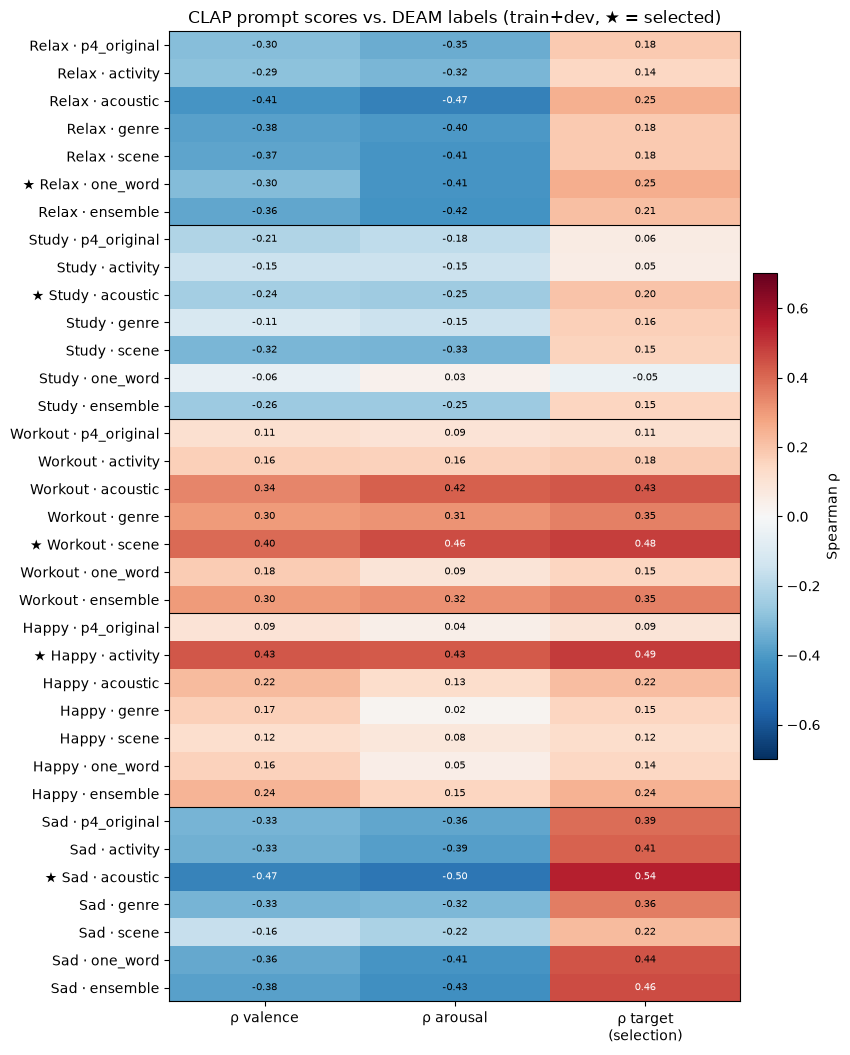

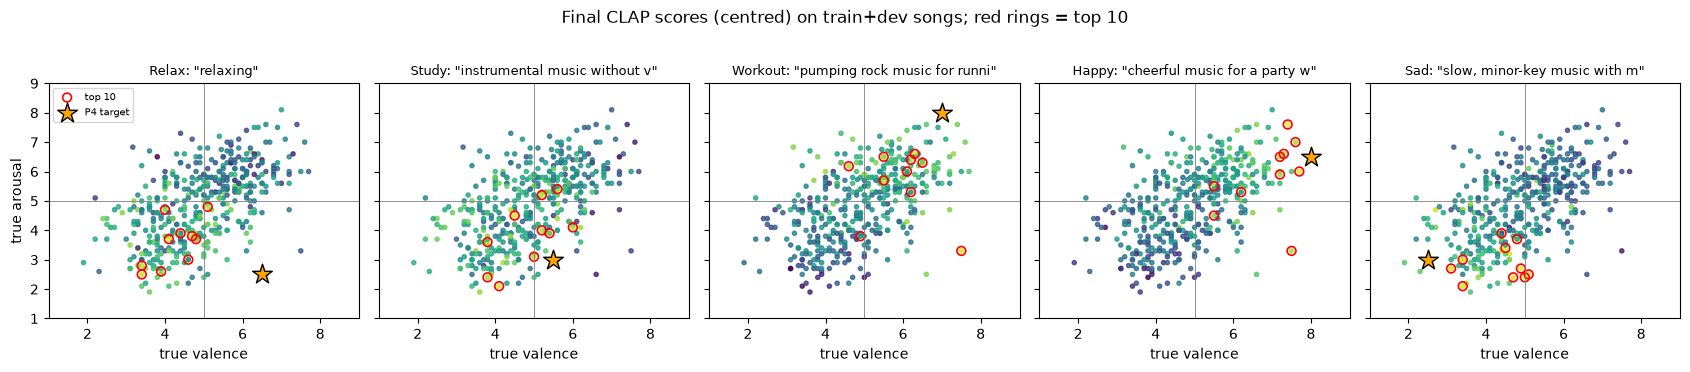

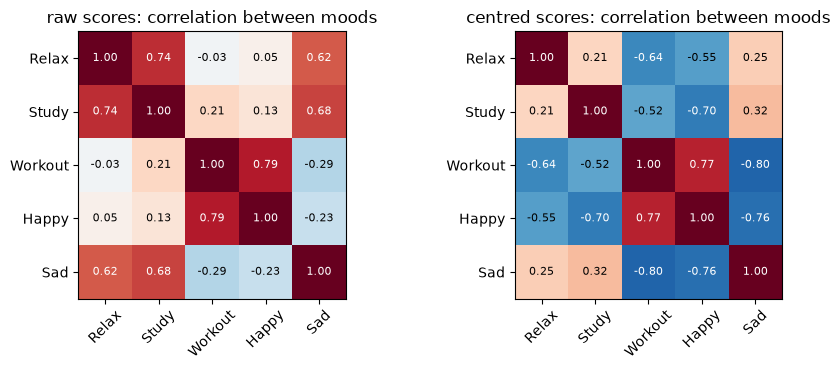

In [9]:
fig, ax = plt.subplots(figsize=(8.6, 0.27 * len(comparison) + 1.2))
mat = comparison[['rho_valence', 'rho_arousal', 'rho_target']].to_numpy()
im = ax.imshow(mat, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto')
ax.set_xticks(range(3), ['ρ valence', 'ρ arousal', 'ρ target\n(selection)'])
ax.set_yticks(range(len(comparison)),
              [f"{'★ ' if s else ''}{m} · {st}" for m, st, s in zip(comparison.mood, comparison['style'], comparison.selected)])
for (i, j), val in np.ndenumerate(mat):
    ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(val) > 0.45 else 'black')
for k in range(1, len(MOODS)):
    ax.axhline(k * PER_MOOD - 0.5, color='k', lw=0.8)
ax.set_title('CLAP prompt scores vs. DEAM labels (train+dev, ★ = selected)')
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Spearman ρ')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'prompt_comparison_heatmap.png'), dpi=150); plt.show()

fp = final_scores(pool, SCORE_MODE)
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharex=True, sharey=True)
for ax, m in zip(axes, MOOD_LIST):
    s = fp[f'clap_{m}'].to_numpy()
    sc = ax.scatter(pool.valence_true, pool.arousal_true, c=s, cmap='viridis', s=9, alpha=0.8)
    top = np.argsort(-s, kind='stable')[:TOP_K]
    ax.scatter(pool.valence_true.iloc[top], pool.arousal_true.iloc[top], facecolors='none', edgecolors='red', s=40, lw=1.2,
               label=f'top {TOP_K}')
    ax.scatter(MOODS[m]['valence'], MOODS[m]['arousal'], marker='*', s=220, c='orange', edgecolors='k', label='P4 target')
    ax.axvline(MIDPOINT, c='gray', lw=0.6); ax.axhline(MIDPOINT, c='gray', lw=0.6)
    ax.set(xlim=(1, 9), ylim=(1, 9), title=f'{m}: "{PROMPT_BANK[m].get(SELECTED[m].split("__")[1], "ensemble")[:28]}"',
           xlabel='true valence')
    ax.title.set_fontsize(9)
axes[0].set_ylabel('true arousal'); axes[0].legend(loc='upper left', fontsize=7)
fig.suptitle(f'Final CLAP scores ({SCORE_MODE}) on train+dev songs; red rings = top {TOP_K}', y=1.02)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'clap_scores_in_va_space.png'), dpi=150, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, mode in zip(axes, ('raw', 'centred')):
    c = np.corrcoef(final_scores(pool, mode).to_numpy().T)
    ax.imshow(c, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(5), MOOD_LIST, rotation=45); ax.set_yticks(range(5), MOOD_LIST)
    for (i, j), val in np.ndenumerate(c):
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(val) > 0.6 else 'black')
    ax.set_title(f'{mode} scores: correlation between moods')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'mood_score_correlation.png'), dpi=150); plt.show()

In [10]:
fd = pd.concat([dev[['song_id', 'valence_true', 'arousal_true']], final_scores(dev, SCORE_MODE)], axis=1)
for m in MOOD_LIST:
    top = fd.sort_values([f'clap_{m}', 'song_id'], ascending=[False, True]).head(5).copy()
    top['in_quadrant'] = in_quadrant(top.valence_true, top.arousal_true, m)
    print(f'--- {m}  (target V={MOODS[m]["valence"]}, A={MOODS[m]["arousal"]})')
    print(top[['song_id', 'valence_true', 'arousal_true', f'clap_{m}', 'in_quadrant']].round(3).to_string(index=False))

sel_txt = CAND_TXT[[candidates.index[candidates.prompt_id == SELECTED[m]][0] for m in MOOD_LIST]]
win_sd = np.array([(win_embs[s] @ sel_txt.T).std(axis=0) for s in pool.song_id if len(win_embs[s]) > 1])
song_sd = final_scores(pool, 'raw').to_numpy().std(axis=0)
print('\nwithin-song std of window scores vs. between-song std of song scores (raw):')
print(pd.DataFrame({'within_song_window_sd': win_sd.mean(axis=0), 'between_song_sd': song_sd}, index=MOOD_LIST).round(4).to_string())

--- Relax  (target V=6.5, A=2.5)
 song_id  valence_true  arousal_true  clap_Relax  in_quadrant
    1436           4.7           3.8       0.216        False
     991           3.1           3.5       0.184        False
     522           3.5           2.7       0.175        False
     560           2.9           4.6       0.174        False
      58           3.3           3.4       0.174        False
--- Study  (target V=5.5, A=3.0)
 song_id  valence_true  arousal_true  clap_Study  in_quadrant
    1134           4.1           2.1       0.174        False
    1721           4.2           2.9       0.143        False
    1306           5.3           5.3       0.126        False
     501           2.5           4.4       0.111        False
    1510           4.1           5.6       0.107        False
--- Workout  (target V=7.0, A=8.0)
 song_id  valence_true  arousal_true  clap_Workout  in_quadrant
    1946           4.0           6.0         0.185        False
    1058           4.0     

## 5 · Complementarity with P2 (dev)

In [11]:
def minmax(x):
    x = np.asarray(x, float)
    return np.full_like(x, 0.5) if np.isclose(x.min(), x.max()) else (x - x.min()) / (x.max() - x.min())

p2 = None
p2_local = os.path.join(P2_OUT_DIR, 'p2_va_for_p4.csv')
try:
    p2, p2_src = (pd.read_csv(p2_local), p2_local) if os.path.exists(p2_local) else read_repo_csv('p2/p2_va_for_p4.csv')
except Exception as e:
    print('P2 predictions unavailable, skipping this diagnostic:', e)
if p2 is not None:
    d = dev.merge(p2[['song_id', 'valence', 'arousal']], on='song_id', how='inner')
    d = pd.concat([d, final_scores(d, SCORE_MODE)], axis=1)
    rows = []
    for m in MOOD_LIST:
        true_sim = emotion_similarity(d.valence_true, d.arousal_true, m)
        q = in_quadrant(d.valence_true.to_numpy(), d.arousal_true.to_numpy(), m)
        p2_sim = emotion_similarity(d.valence.clip(1, 9), d.arousal.clip(1, 9), m).to_numpy()
        clap_n = minmax(d[f'clap_{m}'])
        comb = 0.5 * p2_sim + 0.5 * clap_n
        rows.append({'mood': m, 'rho(CLAP, P2)': spearmanr(clap_n, p2_sim)[0],
                     'rho target: P2 only': spearmanr(p2_sim, true_sim)[0],
                     'rho target: CLAP only': spearmanr(clap_n, true_sim)[0],
                     'rho target: combined': spearmanr(comb, true_sim)[0],
                     'hit@10: P2 only': hit_at_k(p2_sim, q), 'hit@10: CLAP only': hit_at_k(clap_n, q),
                     'hit@10: combined': hit_at_k(comb, q), 'chance': q.mean()})
    complementarity = pd.DataFrame(rows).set_index('mood')
    complementarity.loc['mean'] = complementarity.mean()
    print(f'P2 predictions from {p2_src}; dev songs matched: {len(d)}')
    display(complementarity.round(3))

P2 predictions from p2/p2_va_for_p4.csv; dev songs matched: 75


,"rho(CLAP, P2)",rho target: P2 only,rho target: CLAP only,rho target: combined,hit@10: P2 only,hit@10: CLAP only,hit@10: combined,chance
mood,,,,,,,,
Relax,0.248,0.378,0.268,0.307,0.30,0.00,0.1,0.093
Study,0.112,0.500,0.125,0.267,0.20,0.00,0.0,0.093
Workout,0.602,0.808,0.546,0.709,0.60,0.50,0.5,0.253
Happy,0.444,0.803,0.607,0.783,0.80,0.80,0.9,0.253
Sad,0.435,0.812,0.448,0.697,0.90,0.80,1.0,0.387
mean,0.368,0.660,0.399,0.552,0.56,0.42,0.5,0.216


## 6 · Save outputs

In [12]:
os.makedirs(OUT_DIR, exist_ok=True)
clap_cols = [f'clap_{m}' for m in MOOD_LIST]
all_scores = pd.concat([SCORES[['song_id']], final_scores(SCORES, SCORE_MODE)], axis=1)
all_scores = all_scores.merge(songs[['song_id', 'split']], on='song_id', how='left')
for_p4 = songs[['song_id', 'split']].merge(all_scores.drop(columns='split'), on='song_id', validate='one_to_one')

assert for_p4.song_id.is_unique and len(for_p4) == len(songs)
assert np.isfinite(for_p4[clap_cols].to_numpy()).all()
assert for_p4.split.isin(['train', 'dev', 'test']).all()
tops ={m: tuple(for_p4[for_p4.split == 'dev'].sort_values([f'clap_{m}', 'song_id'], ascending=[False, True]).song_id.head(TOP_K))
        for m in MOOD_LIST}
assert len(set(tops.values())) == len(MOOD_LIST), 'two options give an identical dev top 10'
print('songs per split:', for_p4.split.value_counts().to_dict())

for_p4.round(5).to_csv(os.path.join(OUT_DIR, 'p3_clap_for_p4.csv'), index=False)
all_scores.round(5).to_csv(os.path.join(OUT_DIR, 'p3_clap_scores_all_songs.csv'), index=False)
SCORES.merge(songs[['song_id', 'split']], on='song_id', how='left').round(5).to_csv(
    os.path.join(OUT_DIR, 'prompt_scores_all_prompts.csv'), index=False)
comparison.round(4).to_csv(os.path.join(OUT_DIR, 'prompt_comparison.csv'), index=False)
style_summary.round(4).to_csv(os.path.join(OUT_DIR, 'prompt_style_summary.csv'))
mode_cmp.round(4).to_csv(os.path.join(OUT_DIR, 'scoring_mode_comparison.csv'), index=False)
if p2 is not None:
    complementarity.round(4).to_csv(os.path.join(OUT_DIR, 'complementarity_with_p2_dev.csv'))

sel_rows = comparison[comparison.selected].set_index('mood')
config = {
    'clap_model': CLAP_ID, 'sampling_rate': SR, 'window_seconds': WINDOW_S, 'min_tail_seconds': MIN_TAIL_S,
    'song_score': 'mean over 10 s windows of cosine(audio window, prompt text)',
    'score_mode': SCORE_MODE, 'selection': 'max Spearman(score, true emotion similarity to P4 target) on train+dev',
    'split_source': SPLIT_SOURCE, 'moods': MOODS,
    'selected': {m: {'style': sel_rows.loc[m, 'style'],
                     'prompts': list(PROMPT_BANK[m].values()) if sel_rows.loc[m, 'style'] == 'ensemble'
                                else [PROMPT_BANK[m][sel_rows.loc[m, 'style']]],
                     'pool_metrics': {k: round(float(sel_rows.loc[m, k]), 4)
                                      for k in ('rho_target', 'auc_quadrant', 'hit10_pool', 'hit10_dev')}}
                 for m in MOOD_LIST},
    'prompt_bank': PROMPT_BANK,
    'songs_embedded': int(len(emb_ids)),
}
with open(os.path.join(OUT_DIR, 'p3_clap_config.json'), 'w') as f:
    json.dump(config, f, indent=2)
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))
display(for_p4.head())

songs per split: {'train': 350, 'test': 75, 'dev': 75}
saved to outputs/p3 : ['clap_audio_embeddings.npz', 'clap_scores_in_va_space.png', 'complementarity_with_p2_dev.csv', 'mood_score_correlation.png', 'p3_clap_config.json', 'p3_clap_for_p4.csv', 'p3_clap_scores_all_songs.csv', 'prompt_comparison.csv', 'prompt_comparison_heatmap.png', 'prompt_scores_all_prompts.csv', 'prompt_style_summary.csv', 'scoring_mode_comparison.csv']


,song_id,split,clap_Relax,clap_Study,clap_Workout,clap_Happy,clap_Sad
0,2,train,0.086419,-0.009383,-0.029428,-0.043302,-0.004306
1,3,train,0.001357,0.128343,-0.001043,-0.003590,-0.125067
2,5,test,0.202538,-0.061694,-0.120745,-0.007979,-0.012120
3,7,train,-0.023672,0.040027,0.073051,0.141916,-0.231322
4,8,dev,0.020123,0.088248,-0.039738,0.027772,-0.096404


## 7 · Inference helpers

In [13]:
SEL_TXT = CAND_TXT[[candidates.index[candidates.prompt_id == SELECTED[m]][0] for m in MOOD_LIST]]

def clap_scores_from_audio(path):
    raw = embed_song(path).astype(np.float32).mean(axis=0) @ SEL_TXT.T
    out = raw - raw.mean() if SCORE_MODE == 'centred' else raw
    return {f'clap_{m}': round(float(x), 5) for m, x in zip(MOOD_LIST, out)}

def score_custom_prompt(text, split='dev', k=5):
    s = EMB @ embed_text([text])[0]
    df = pd.DataFrame({'song_id': emb_ids, 'score': s}).merge(songs[['song_id', 'split', 'valence_true', 'arousal_true']],
                                                              on='song_id')
    return df[df.split == split].sort_values(['score', 'song_id'], ascending=[False, True]).head(k).reset_index(drop=True)

ex = songs[songs.split == 'dev'].iloc[0]
print(f'song {ex.song_id}:', clap_scores_from_audio(ex.path))
print('matches cached row:', for_p4.set_index('song_id').loc[ex.song_id, clap_cols].round(5).to_dict())
display(score_custom_prompt('music for cooking dinner with family'))

song 8: {'clap_Relax': 0.02012, 'clap_Study': 0.08825, 'clap_Workout': -0.03974, 'clap_Happy': 0.02777, 'clap_Sad': -0.0964}
matches cached row: {'clap_Relax': 0.02012000046670437, 'clap_Study': 0.08824999630451202, 'clap_Workout': -0.039739999920129776, 'clap_Happy': 0.02776999957859516, 'clap_Sad': -0.09640000015497208}


,song_id,score,split,valence_true,arousal_true
0,1668,0.347026,dev,5.5,5.5
1,635,0.342344,dev,6.6,7.6
2,915,0.341940,dev,5.0,5.2
3,514,0.314310,dev,4.3,5.8
4,1141,0.305274,dev,4.5,3.6


## 8 · Final test

In [14]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    test = lab[lab.split == 'test'].reset_index(drop=True)
    ft = pd.concat([test, final_scores(test, SCORE_MODE)], axis=1)
    test_metrics = pd.DataFrame([dict(mood=m, **prompt_metrics(ft, ft, f'clap_{m}', m)) for m in MOOD_LIST]).set_index('mood')
    test_metrics = test_metrics.drop(columns=['hit10_pool', 'chance_pool']).rename(
        columns={'hit10_dev': 'hit10_test', 'chance_dev': 'chance_test'})
    test_metrics.to_csv(os.path.join(OUT_DIR, 'final_test_clap_metrics.csv'))
    display(test_metrics.round(3))
else:
    print('Test split untouched (RUN_FINAL_TEST = False).')

Test split untouched (RUN_FINAL_TEST = False).
